Test in order to have a look at the paths

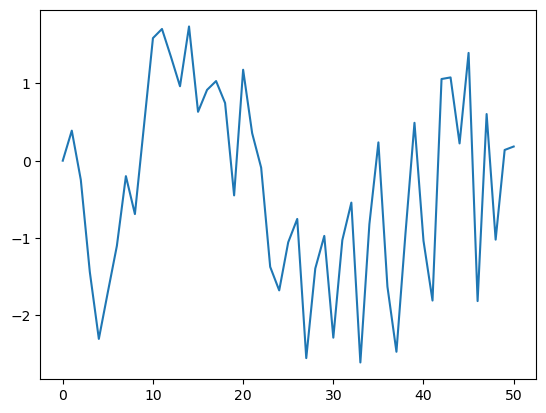

In [11]:
import importlib
import simulated_data

importlib.reload(simulated_data)
from simulated_data import fractional_BM_paths

N = 50
T = 50

path, bs = fractional_BM_paths(alpha = -0.3,T = T, N = N)

import matplotlib.pyplot as plt
plt.plot(path)
plt.show()

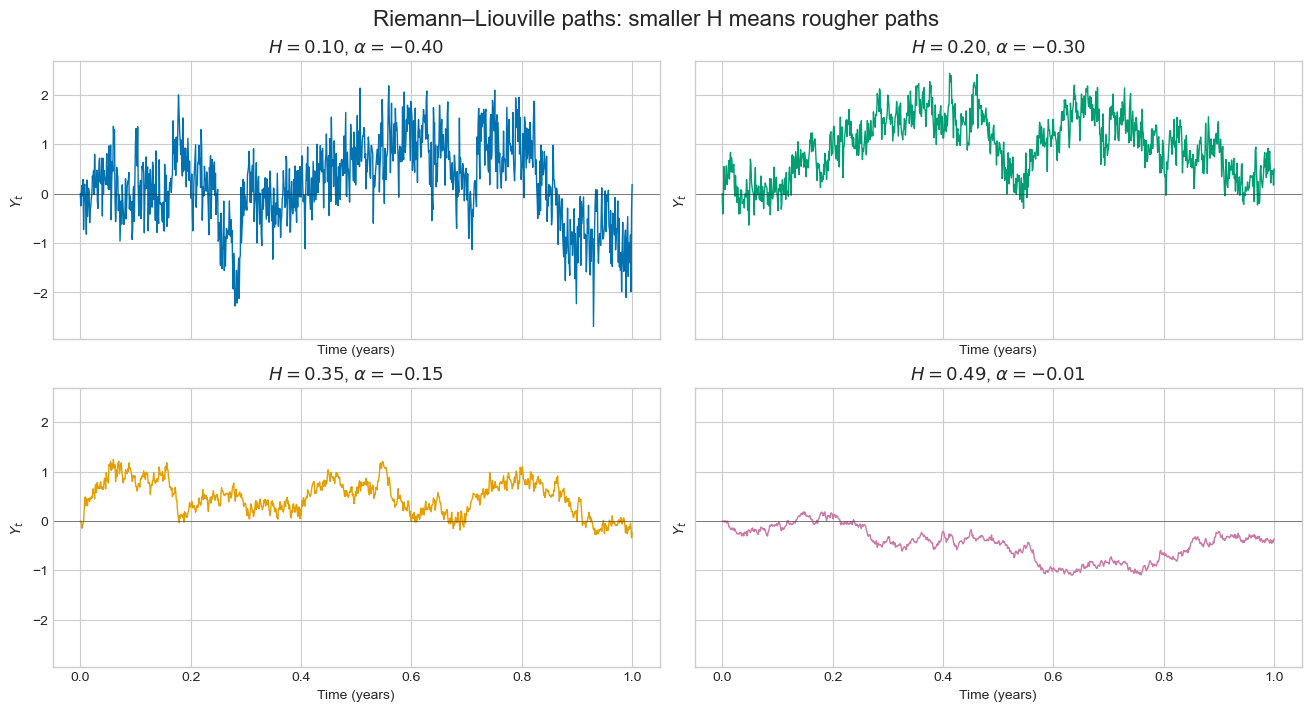

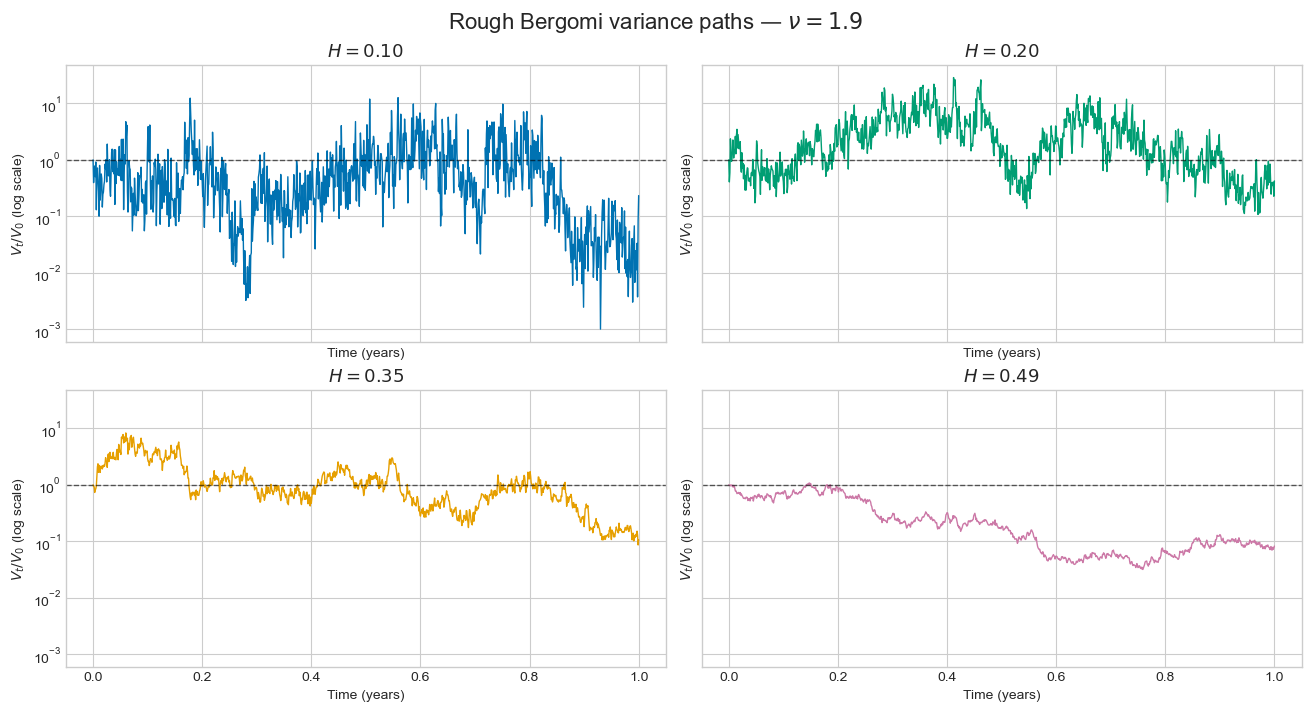

In [12]:
import importlib
import numpy as np
import matplotlib.pyplot as plt
import simulated_data

importlib.reload(simulated_data)

# Simulation parameters
N = 1000
T = 1.0                         # One year
H_values = [0.10, 0.20, 0.35, 0.49]
V0 = 0.235**2
nu = 1.9

t = np.linspace(0, T, N + 1)
colors = ["#0072B2", "#009E73", "#E69F00", "#CC79A7"]

# Reproducible simulations
np.random.seed(42)

paths = {}
variances = {}

for H in H_values:
    alpha = H - 0.5

    y, bs = simulated_data.fractional_BM_paths(
        alpha=alpha, T=T, N=N
    )

    paths[H] = y
    variances[H] = V0 * np.exp(
        nu * y - 0.5 * nu**2 * t**(2 * H)
    )

with plt.style.context("seaborn-v0_8-whitegrid"):

    # Figure 1: RL Gaussian paths, with common axis scales
    fig, axes = plt.subplots(
        2, 2, figsize=(13, 7), sharex=True, sharey=True,
        constrained_layout=True
    )

    for ax, H, color in zip(axes.flat, H_values, colors):
        ax.plot(t, paths[H], color=color, linewidth=1)
        ax.axhline(0, color="black", linewidth=0.7, alpha=0.4)
        ax.set_title(
            rf"$H={H:.2f}$, $\alpha={H - 0.5:.2f}$",
            fontsize=13
        )
        ax.set_xlabel("Time (years)")
        ax.set_ylabel(r"$Y_t$")

    fig.suptitle(
        "Riemann–Liouville paths: smaller H means rougher paths",
        fontsize=16
    )

    # Figure 2: Variance relative to its initial level
    fig, axes = plt.subplots(
        2, 2, figsize=(13, 7), sharex=True, sharey=True,
        constrained_layout=True
    )

    for ax, H, color in zip(axes.flat, H_values, colors):
        ax.plot(t, variances[H] / V0, color=color, linewidth=1)
        ax.axhline(
            1, color="black", linestyle="--",
            linewidth=1, alpha=0.6
        )
        ax.set_yscale("log")
        ax.set_title(rf"$H={H:.2f}$", fontsize=13)
        ax.set_xlabel("Time (years)")
        ax.set_ylabel(r"$V_t/V_0$ (log scale)")

    fig.suptitle(
        rf"Rough Bergomi variance paths — $\nu={nu}$",
        fontsize=16
    )

    plt.show()